In [1]:
rm(list=ls()) # clean/reset environment 
library(here)
library(zCompositions)
library(phyloseq)
library(ggplot2)
library(vegan)
library(microViz)
library(dplyr)
library(plotly)

here() starts at /Users/theco/Projects/niche_vs_neutral

Warning message:
"package 'zCompositions' was built under R version 4.3.3"
Loading required package: MASS

Loading required package: NADA

Loading required package: survival

Warning message:
"package 'survival' was built under R version 4.3.3"

Attaching package: 'NADA'


The following object is masked from 'package:stats':

    cor


Loading required package: truncnorm

Warning message:
"package 'vegan' was built under R version 4.3.3"
Loading required package: permute

Loading required package: lattice

This is vegan 2.6-8

Warning message:
"package 'microViz' was built under R version 4.3.3"
microViz version 0.12.4 - Copyright (C) 2021-2024 David Barnett
! Website: https://david-barnett.github.io/microViz
v Useful?  For citation details, run: `citation("microViz")`
x Silence? `suppressPackageStartupMessages(library(microViz))`

Attaching package: 'dplyr'


The following object is masked from 'package:MASS':

    select


The 

In [2]:
mapfile = here("1_samples_properties", "Metadata_singleTree_wDirich.tsv")
otufile = here("1_dada2", "otu_table_treeholes_dada2_renamed_clean_red.tsv")
repset = here("1_dada2", "repset_treeholes_dada2_phyloseq.txt")

In [3]:
# physeq = import_qiime(otufilename = otufile, mapfilename = mapfile, refseqfilename = repset)
# physeq

In [7]:
fileOTU <- "otu_table_treeholes_dada2_renamed_clean.txt"
fileSample <- "Metadata_singleTree_wDirich-K10.tsv"
fileTaxonomy <- "taxonomy.list"

# --- Minimum number of reads to keep a sample/taxa
Nprune.sample <- 1000
Nprune.taxa <- 10

In [5]:
# --- Load OTUs
otu.in=read.csv(here("1_dada2", fileOTU), sep = "\t", row.names = 1)
head(otu.in)[1:5,1:5]

otu.pseq=otu_table(as.matrix(otu.in), taxa_are_rows = TRUE)

,F.D.DNA.P1.A3.A.01.ID3.3.15.THS.2.16S.3,F.D.DNA.P1.A3.A.02.ID3.3.15.THS.10.16S.3,F.D.DNA.P1.A3.A.03.ID10.3.15.THS.9.16S.3,F.D.DNA.P1.A3.A.04.ID7.7.15.THS.6.16S.3,F.D.DNA.P1.A3.A.05.ID10.2.15.THS.4.16S.3
,<int>,<int>,<int>,<int>,<int>
ASV_1,170,4,371,213,66
ASV_10,0,30,0,0,1
ASV_100,13,0,17,23,3
ASV_1000,2,0,8,0,1
ASV_1001,1,0,0,8,1


In [8]:
# --- Load samples metadata
meta <- import_qiime_sample_data(here("1_samples_properties", fileSample))
meta <- meta[meta$Type == "DNA"]

In [10]:
dim(otu.in)
dim(otu.pseq)

[1] 8566  213

[1] 8566  213

In [34]:
dim(otu.pseq)[2] - dim(meta)[1]

[1] -15

In [31]:
# Samples present in otu.pseq and no present in meta
length(setdiff(colnames(otu.pseq), meta$ID.Sample))
setdiff(colnames(otu.pseq), meta$ID.Sample)

[1] 21

[1] "F.D.DNA.P1.A3.B.06.ID17.2.15.THS.2.16S.3"      
 [2] "F.D.DNA.P1.A3.C.03.IDCONTROL.THS.CONTROL.16S.3"
 [3] "F.D.DNA.P1.A3.C.05.ID10.2.15.THS.6.16S.3"      
 [4] "F.D.DNA.P1.A3.C.08.IDCONTROL.THS.CONTROL.16S.3"
 [5] "F.D.DNA.P1.A3.D.08.ID03.11.15.THS.1.16S.3"     
 [6] "F.D.DNA.P1.A3.E.05.ID10.2.15.THS.8.16S.3"      
 [7] "F.D.DNA.P1.A3.G.06.ID17.2.15.THS.8.16S.3"      
 [8] "F.D.DNA.P1.A3.H.10.IDCONTROL.THS.CONTROL.16S.3"
 [9] "F.D.DNA.P2.B3.A.09.ID01.09.15.THS.9.16S.3"     
[10] "F.D.DNA.P2.B3.C.03.IDCONTROL.THS.CONTROL.16S.3"
[11] "F.D.DNA.P2.B3.C.09.IDCONTROL.THS.CONTROL.16S.3"
[12] "F.D.DNA.P2.B3.D.03.ID17.11.15.THS.1.16S.3"     
[13] "F.D.DNA.P2.B3.D.04.ID17.11.15.THS.9.16S.3"     
[14] "F.D.DNA.P2.B3.E.10.ID06.10.15.THS.1.16S.3"     
[15] "F.D.DNA.P2.B3.F.04.IDCONTROL.THS.CONTROL.16S.3"
[16] "F.D.DNA.P2.B3.F.06.ID18.11.14.THS.7.16S.3"     
[17] "F.D.DNA.P2.B3.G.11.IDCONTROL.THS.CONTROL.16S.3"
[18] "F.D.DNA.P2.B3.H.05.IDCONTROL.THS.CONTROL.16S.3"
[19] "F.D.DNA.P2.B3.H.06.ID18.11.14.THS.9.16S.3"     
[20] "F.D.DNA.P3.C3.D.05.ID23.06.15.THS.7.16S.3"     
[21] "F.D.DNA.P3.C3.F.04.IDCONTROL.THS.CONTROL.16S.3"

In [29]:
# Samples present in meta and no present in out.pseq
length(setdiff(meta$ID.Sample, colnames(otu.pseq)))
setdiff(meta$ID.Sample, colnames(otu.pseq))

[1] 36

[1] "F.D.DNA.P1.A3.G.07.ID24.2.15.THS.7.16S.3"      
 [2] "F.D.DNA.P1.A3.G.08.ID03.11.15.THS.4.16S.3"     
 [3] "F.D.DNA.P1.A3.G.10.ID29.09.15.THS.10.16S.3"    
 [4] "F.D.DNA.P1.A3.G.12.ID11.05.15.THS.8.16S.3"     
 [5] "F.D.DNA.P1.A3.H.01.ID3.3.15.THS.9.16S.3"       
 [6] "F.D.DNA.P1.A3.H.02.ID10.3.15.THS.8.16S.3"      
 [7] "F.D.DNA.P1.A3.H.03.ID7.7.15.THS.5.16S.3"       
 [8] "F.D.DNA.P1.A3.H.06.ID17.2.15.THS.9.16S.3"      
 [9] "F.D.DNA.P1.A3.H.08.ID03.11.15.THS.5.16S.3"     
[10] "F.D.DNA.P1.A3.H.11.ID14.03.15.THS.9.16S.3"     
[11] "F.D.DNA.P1.A3.H.12.ID11.05.15.THS.9.16S.3"     
[12] "F.D.DNA.P2.B3.A.01.ID30.06.15.THS.1.16S.3"     
[13] "F.D.DNA.P2.B3.A.02.ID30.06.15.THS.10.16S.3"    
[14] "F.D.DNA.P2.B3.A.12.ID04.08.15.THS.3.16S.3"     
[15] "F.D.DNA.P3.C3.A.08.ID17.11.15.RAIN.North.16S.3"
[16] "F.D.DNA.P3.C3.A.09.ID13.10.15.RAIN.South.16S.3"
[17] "F.D.DNA.P3.C3.B.09.ID13.10.15.RAIN.East.16S.3" 
[18] "F.D.DNA.P3.C3.C.06.ID29.9.15.RAIN.East.16S.3"  
[19] "F.D.DNA.P3.C3.C.07.ID04.08.15.RAIN.East.16S.3" 
[20] "F.D.DNA.P3.C3.C.08.ID17.11.15.RAIN.East.16S.3" 
[21] "F.D.DNA.P3.C3.C.10.ID10.02.15.RAIN.East.16S.3" 
[22] "F.D.DNA.P3.C3.C.11.ID19.12.14.RAIN.East.16S.3" 
[23] "F.D.DNA.P3.C3.C.12.ID24.02.15.RAIN.East.16S.3" 
[24] "F.D.DNA.P3.C3.D.08.ID17.11.15.RAIN.West.16S.3" 
[25] "F.D.DNA.P3.C3.D.10.ID10.02.15.RAIN.West.16S.3" 
[26] "F.D.DNA.P3.C3.D.11.ID19.12.14.RAIN.West.16S.3" 
[27] "F.D.DNA.P3.C3.D.12.ID21.05.15.RAIN.South.16S.3"
[28] "F.D.DNA.P3.C3.E.01.ID09.06.15.THS.5.16S.3"     
[29] "F.D.DNA.P3.C3.E.09.ID03.03.15.RAIN.East.16S.3" 
[30] "F.D.DNA.P3.C3.E.12.ID21.05.15.RAIN.East.16S.3" 
[31] "F.D.DNA.P3.C3.F.06.ID06.10.15.RAIN.East.16S.3" 
[32] "F.D.DNA.P3.C3.F.07.ID01.09.15.RAIN.East.16S.3" 
[33] "F.D.DNA.P3.C3.F.12.ID21.05.15.RAIN.West.16S.3" 
[34] "F.D.DNA.P3.C3.G.10.ID14.01.15.RAIN.East.16S.3" 
[35] "F.D.DNA.P3.C3.G.12.ID14.04.15.RAIN.South.16S.3"
[36] "F.D.DNA.P3.C3.H.01.ID09.06.15.THS.8.16S.3"

In [19]:
colnames(meta)

[1] "ID.Sample"                 "Type"                     
 [3] "Plate"                     "Row"                      
 [5] "Column"                    "Date"                     
 [7] "R.date"                    "Calendar"                 
 [9] "Month.No"                  "Month"                    
[11] "Sample.type"               "Location"                 
[13] "Moisture"                  "Wet"                      
[15] "F.D"                       "Max.Lum"                  
[17] "nmol.g"                    "Distance.from.previous.TH"
[19] "SA"                        "Volume"                   
[21] "Depth"                     "Deg.North"                
[23] "Air.Temp"                  "Grass.Temp"               
[25] "Soil.Temp2"                "Soil.Temp4"               
[27] "Air.Temp.max"              "Air.Temp.min"             
[29] "Grass.Temp.max"            "Grass.Temp.min"           
[31] "Rainfall"                  "Dought_days"              
[33] "Biomass"                   "Dirichlet"

In [26]:
meta2 <- meta[meta$Sample.type == "THS"]

In [36]:
dim(meta)
dim(meta2)
dim(otu.pseq)

[1] 228  34

[1] 208  34

[1] 8566  213

In [27]:
otu.meta <- otu.pseq[, rownames(meta2)]
dim(otu.meta)

ERROR: Error in as(x, "matrix")[i, j, drop = FALSE]: subscript out of bounds


In [37]:
# --- Load taxonomy and clean it 
col_names <- c("Kingdom","Phylum",
                    "Class","Order","Family","Genus","taxa_id")

taxa.in <- read.table(here("1_dada2", fileTaxonomy), sep = ";", skip = 1, col.names = col_names)

rownames(taxa.in)=taxa.in$taxa_id

taxa.in=subset(taxa.in,select=-c(taxa_id))
tax.pseq = tax_table(as.matrix(taxa.in))

In [45]:
# Preprocessing (controls) ------------------
# --- Control that there are no empty rows/columns 
which(taxa_sums(otu.pseq) == 0) # Null
otu.pseq = prune_taxa(taxa_sums(otu.pseq) > 0, otu.pseq) # delete these guys
any(taxa_sums(otu.pseq) == 0) # double check (FALSE)
which(sample_sums(otu.pseq) == 0)
otu.pseq = prune_samples(sample_sums(otu.pseq) > 0, otu.pseq)
any(sample_sums(otu.pseq) == 0) # double check (FALSE)

named integer(0)

[1] FALSE

named integer(0)

[1] FALSE

In [46]:

# --- Check the distribution of samples and taxa
readsumsdf = data.frame(nreads = sort(taxa_sums(otu.pseq), TRUE), 
                        sorted = 1:ntaxa(otu.pseq),type = "ASVs")
readsumsdf = rbind(readsumsdf, data.frame(nreads = sort(sample_sums(otu.pseq), TRUE), 
                                          sorted = 1:nsamples(otu.pseq), type = "Samples"))

In [132]:
# # ....... plot distribution
# file.out = here("3.1_Neutral_NMGS", "Plot_Number_reads.pdf")
# pdf(file = file.out, width = 10)
# title = "Total number of reads"
# p = ggplot(readsumsdf, aes(x = sorted, y = nreads)) + geom_bar(stat = "identity")
# p = p + ggtitle(title) + scale_y_log10() + 
#   facet_wrap(~type, 1, scales = "free") + 
#   theme_bw() +
#   theme(axis.title = element_text(size = 22),
#         axis.text = element_text(size = 16),
#         strip.text = element_text(size = 25)) 
# print(p)
# dev.off()
# min(sample_sums(otu.pseq)) # The minimum sample sum is 1

In [49]:

# --- Remove samples with less than 1K reads and taxa with less than 10
otu.pseq = prune_taxa(taxa_sums(otu.pseq) > Nprune.taxa, otu.pseq) # delete these guys
otu.pseq = prune_samples(sample_sums(otu.pseq) > Nprune.sample, otu.pseq)
min(sample_sums(otu.pseq))
min(taxa_sums(otu.pseq))

[1] 1837

[1] 11

## Creating NMDS through phyloseq

In [50]:

# Finally, create a single phyloseq object
pseq <- merge_phyloseq(otu.pseq, meta, tax.pseq)

In [51]:
pseq

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 8205 taxa and 192 samples ]
sample_data() Sample Data:       [ 192 samples by 34 sample variables ]
tax_table()   Taxonomy Table:    [ 8205 taxa by 6 taxonomic ranks ]

## Some descriptives

In [52]:
# Load Necessary Libraries and Data
ps <- pseq
# Number of Samples and Taxa
nsamples(ps)  # Number of samples
ntaxa(ps)     # Number of taxa (OTUs/ASVs)


[1] 192

[1] 8205

In [53]:

# Sample Variables
sample_variables(ps)  # List of variables in sample data

# Taxonomic Ranks
rank_names(ps)  # Taxonomic ranks available


[1] "ID.Sample"                 "Type"                     
 [3] "Plate"                     "Row"                      
 [5] "Column"                    "Date"                     
 [7] "R.date"                    "Calendar"                 
 [9] "Month.No"                  "Month"                    
[11] "Sample.type"               "Location"                 
[13] "Moisture"                  "Wet"                      
[15] "F.D"                       "Max.Lum"                  
[17] "nmol.g"                    "Distance.from.previous.TH"
[19] "SA"                        "Volume"                   
[21] "Depth"                     "Deg.North"                
[23] "Air.Temp"                  "Grass.Temp"               
[25] "Soil.Temp2"                "Soil.Temp4"               
[27] "Air.Temp.max"              "Air.Temp.min"             
[29] "Grass.Temp.max"            "Grass.Temp.min"           
[31] "Rainfall"                  "Dought_days"              
[33] "Biomass"                   "Dirichlet"

[1] "Kingdom" "Phylum"  "Class"   "Order"   "Family"  "Genus"

In [114]:

# View Sample Metadata
# head(sample_data(ps))

# Examine OTU/ASV Table
# otu_table(ps)[1:5, 1:5]  # View a subset of the OTU table

# Check Taxonomy Assignments
# tax_table(ps)[1:5, ]  # View a subset of the taxonomy table


In [54]:

# Assess Sequencing Depth

# Summary Statistics
sample_depths <- sample_sums(ps)
summary(sample_depths)


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   2486    6575    8562    9217   11438   24298 

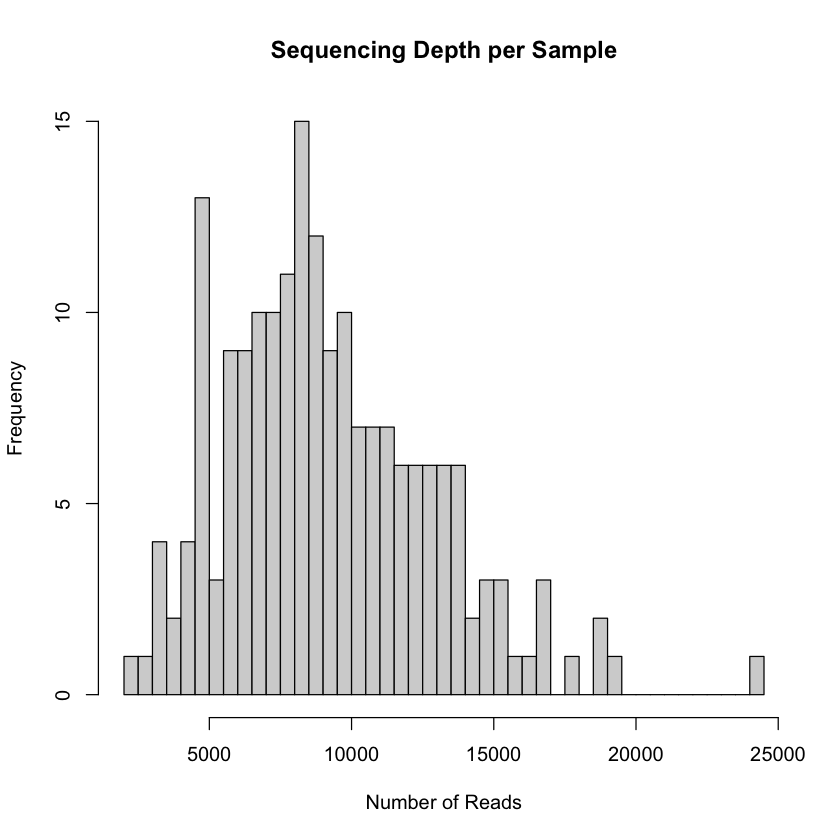

In [55]:

# Histogram of Read Counts
hist(sample_depths, breaks = 50, main = "Sequencing Depth per Sample",
     xlab = "Number of Reads", ylab = "Frequency")


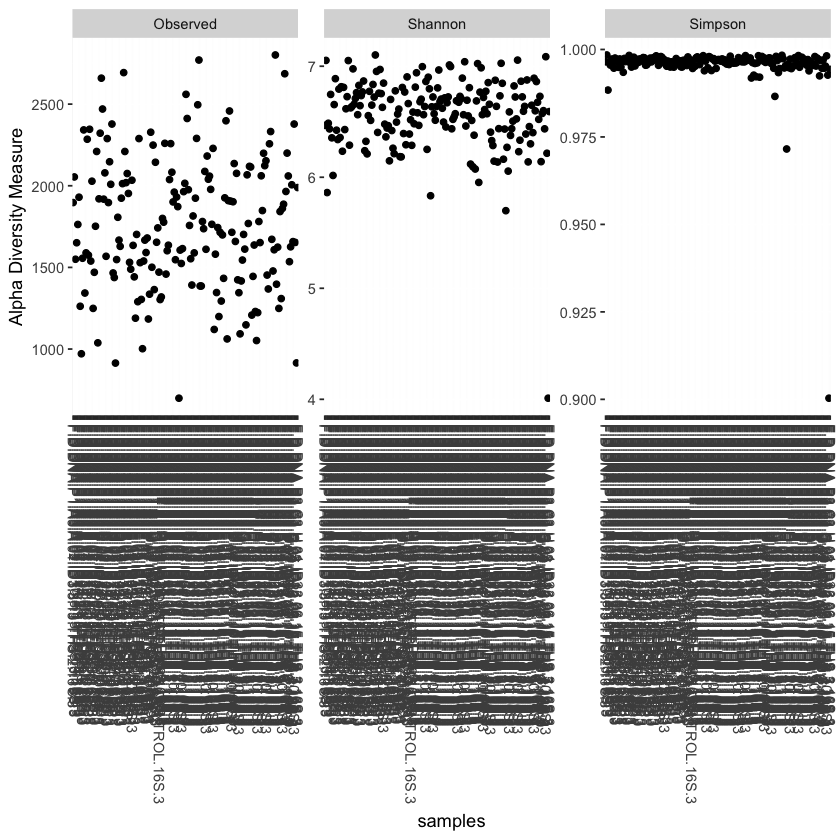

In [56]:

# Explore Alpha Diversity
plot_richness(ps, measures = c("Observed", "Shannon", "Simpson"))


In [60]:
sample_variables(ps)

[1] "ID.Sample"                 "Type"                     
 [3] "Plate"                     "Row"                      
 [5] "Column"                    "Date"                     
 [7] "R.date"                    "Calendar"                 
 [9] "Month.No"                  "Month"                    
[11] "Sample.type"               "Location"                 
[13] "Moisture"                  "Wet"                      
[15] "F.D"                       "Max.Lum"                  
[17] "nmol.g"                    "Distance.from.previous.TH"
[19] "SA"                        "Volume"                   
[21] "Depth"                     "Deg.North"                
[23] "Air.Temp"                  "Grass.Temp"               
[25] "Soil.Temp2"                "Soil.Temp4"               
[27] "Air.Temp.max"              "Air.Temp.min"             
[29] "Grass.Temp.max"            "Grass.Temp.min"           
[31] "Rainfall"                  "Dought_days"              
[33] "Biomass"                   "Dirichlet"

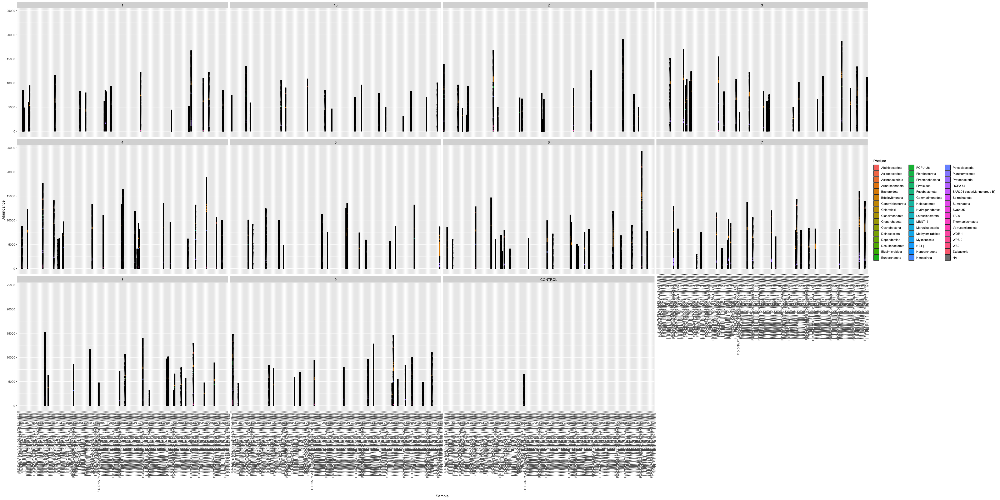

In [68]:

# Visualize Taxonomic Composition

# At Phylum Level
options(repr.plot.width = 40, repr.plot.height = 20)  # Increase plot size for better visibility
plot_bar(ps, fill = "Phylum") +
  facet_wrap(~ Location) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1),
        strip.text = element_text(size = 10))


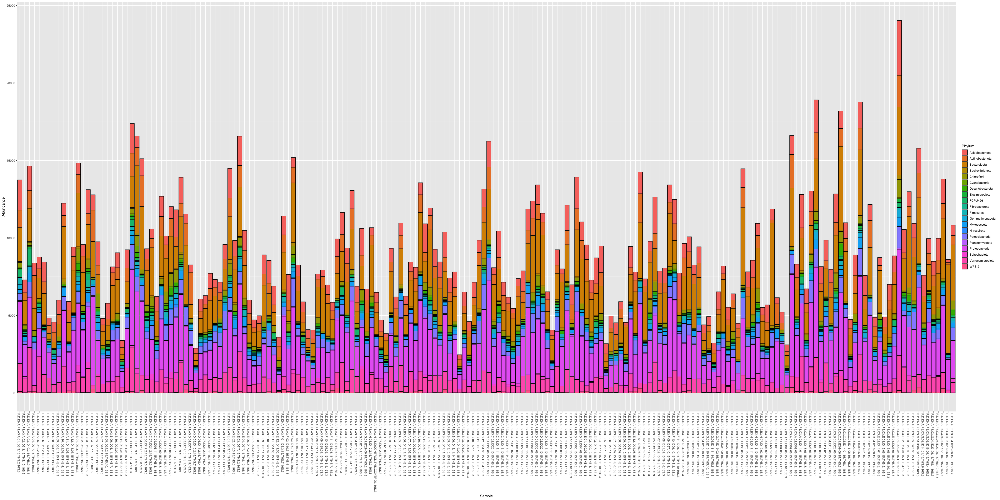

In [69]:

# Aggregate Less Abundant Taxa
ps_phylum <- tax_glom(ps, taxrank = "Phylum")
top20 <- names(sort(taxa_sums(ps_phylum), decreasing = TRUE))[1:20]
ps_top20 <- prune_taxa(top20, ps_phylum)
plot_bar(ps_top20, fill = "Phylum")


Square root transformation
Wisconsin double standardization
Run 0 stress 0.1189213 
Run 1 stress 0.1364187 
Run 2 stress 0.1394884 
Run 3 stress 0.1373669 
Run 4 stress 0.1404285 
Run 5 stress 0.1290482 
Run 6 stress 0.1247353 
Run 7 stress 0.118922 
... Procrustes: rmse 0.0002978324  max resid 0.003706401 
... Similar to previous best
Run 8 stress 0.1191148 
... Procrustes: rmse 0.00451266  max resid 0.06141719 
Run 9 stress 0.1544668 
Run 10 stress 0.1354689 
Run 11 stress 0.1301228 
Run 12 stress 0.1348604 
Run 13 stress 0.1261999 
Run 14 stress 0.139775 
Run 15 stress 0.1191148 
... Procrustes: rmse 0.004515902  max resid 0.06145347 
Run 16 stress 0.1247119 
Run 17 stress 0.1191148 
... Procrustes: rmse 0.004510572  max resid 0.06139956 
Run 18 stress 0.1247353 
Run 19 stress 0.1544697 
Run 20 stress 0.1529316 
*** Best solution repeated 1 times


Warning message:
"The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
i you have requested 7 values. Consider specifying shapes manually if you need
  that many have them."
Warning message:
"Removed 59 rows containing missing values or values outside the scale range
(`geom_point()`)."


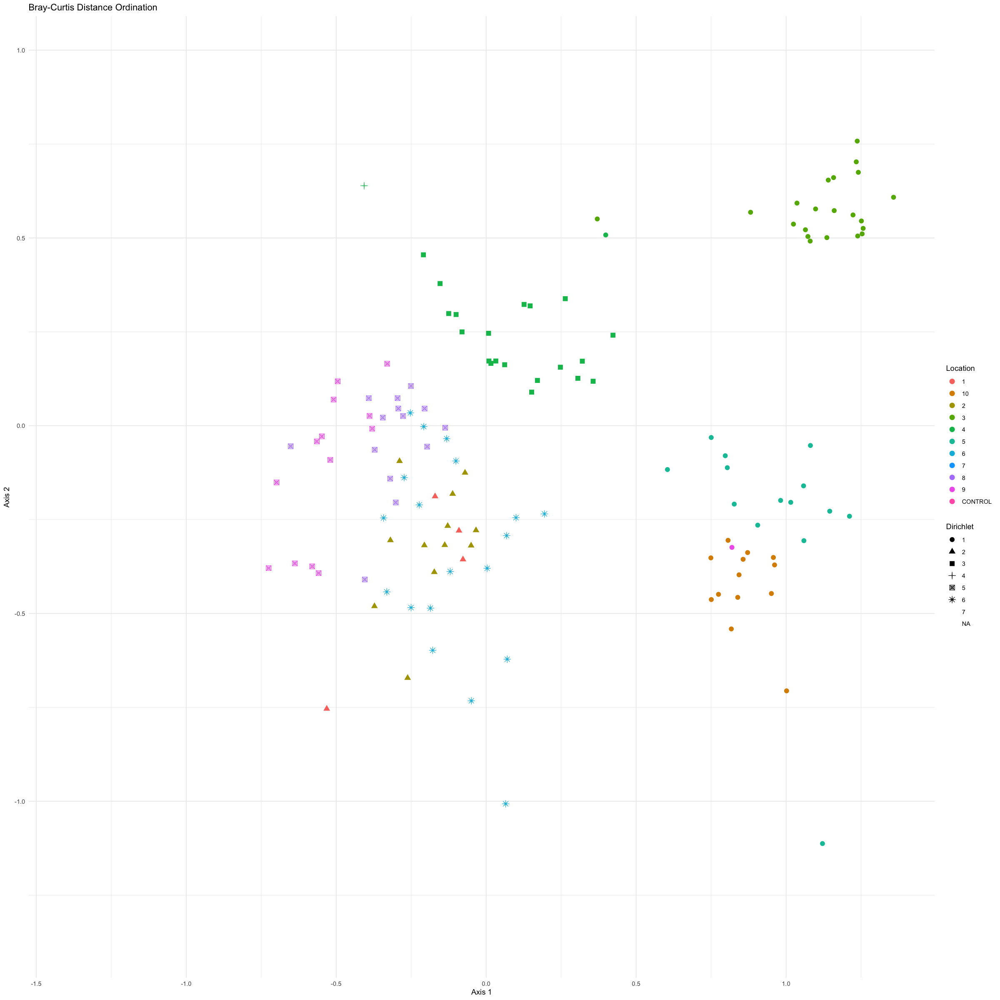

In [ ]:

# Identify and Remove Low-Abundance Taxa
ps_filtered <- filter_taxa(ps, function(x) sum(x > 0) > (0.05 * length(x)), TRUE)

# Convert Counts to Relative Abundances
ps_rel <- transform_sample_counts(ps_filtered, function(x) x / sum(x))

# Perform Ordination Analysis
ordination <- ordinate(ps, method = "NMDS", distance = "bray")

options(repr.plot.width = 20, repr.plot.height = 20)  # Increase plot size for better visibility
sample_data(ps_rel)$Dirichlet <- as.factor(sample_data(ps_rel)$Dirichlet)
plot_ordination(ps_rel, ordination, color = "Location", shape = "Dirichlet") +
  geom_point(size = 3) +
  labs(title = "Bray-Curtis Distance Ordination", x = "Axis 1", y = "Axis 2") +
  theme_minimal()

Warning message:
"The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
i you have requested 11 values. Consider specifying shapes manually if you need
  that many have them."
Warning message:
"Removed 80 rows containing missing values or values outside the scale range
(`geom_point()`)."


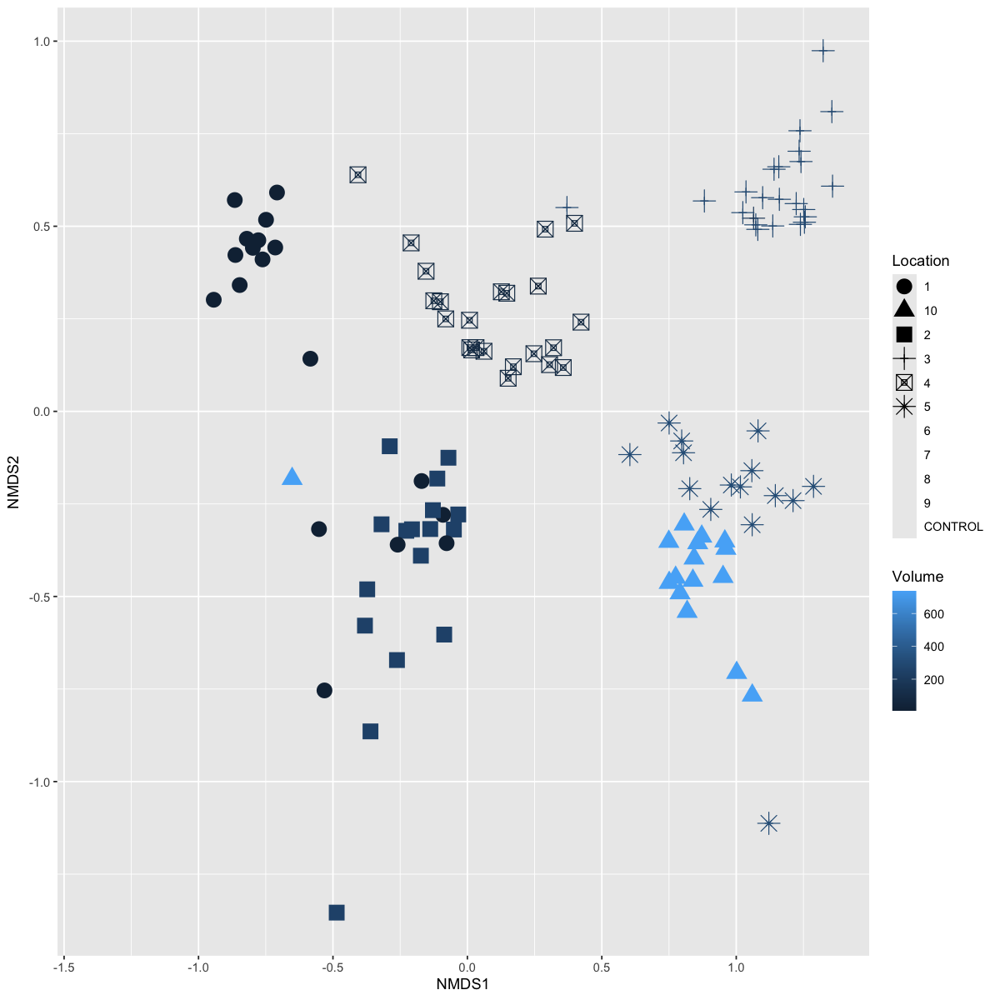

In [92]:

# Check for Batch Effects
options(repr.plot.width = 10, repr.plot.height = 10)  # Increase plot size for better visibility
plot_ordination(ps_rel, ordination, color = "Volume", shape = "Location") +
geom_point(size = 5)


In [93]:

# Generate Rarefaction Curves
rarecurve(t(otu_table(ps_filtered)), step = 1000, cex = 0.5)


ERROR: Error in as(x, "matrix")[i, j, drop = FALSE]: (subscript) logical subscript too long


In [96]:
sample_variables(ps)

[1] "ID.Sample"                 "Type"                     
 [3] "Plate"                     "Row"                      
 [5] "Column"                    "Date"                     
 [7] "R.date"                    "Calendar"                 
 [9] "Month.No"                  "Month"                    
[11] "Sample.type"               "Location"                 
[13] "Moisture"                  "Wet"                      
[15] "F.D"                       "Max.Lum"                  
[17] "nmol.g"                    "Distance.from.previous.TH"
[19] "SA"                        "Volume"                   
[21] "Depth"                     "Deg.North"                
[23] "Air.Temp"                  "Grass.Temp"               
[25] "Soil.Temp2"                "Soil.Temp4"               
[27] "Air.Temp.max"              "Air.Temp.min"             
[29] "Grass.Temp.max"            "Grass.Temp.min"           
[31] "Rainfall"                  "Dought_days"              
[33] "Biomass"                   "Dirichlet"

Warning message in scale_fill_gradient(low = low, high = high, trans = trans, na.value = na.value):
"log-4 transformation introduced infinite values."


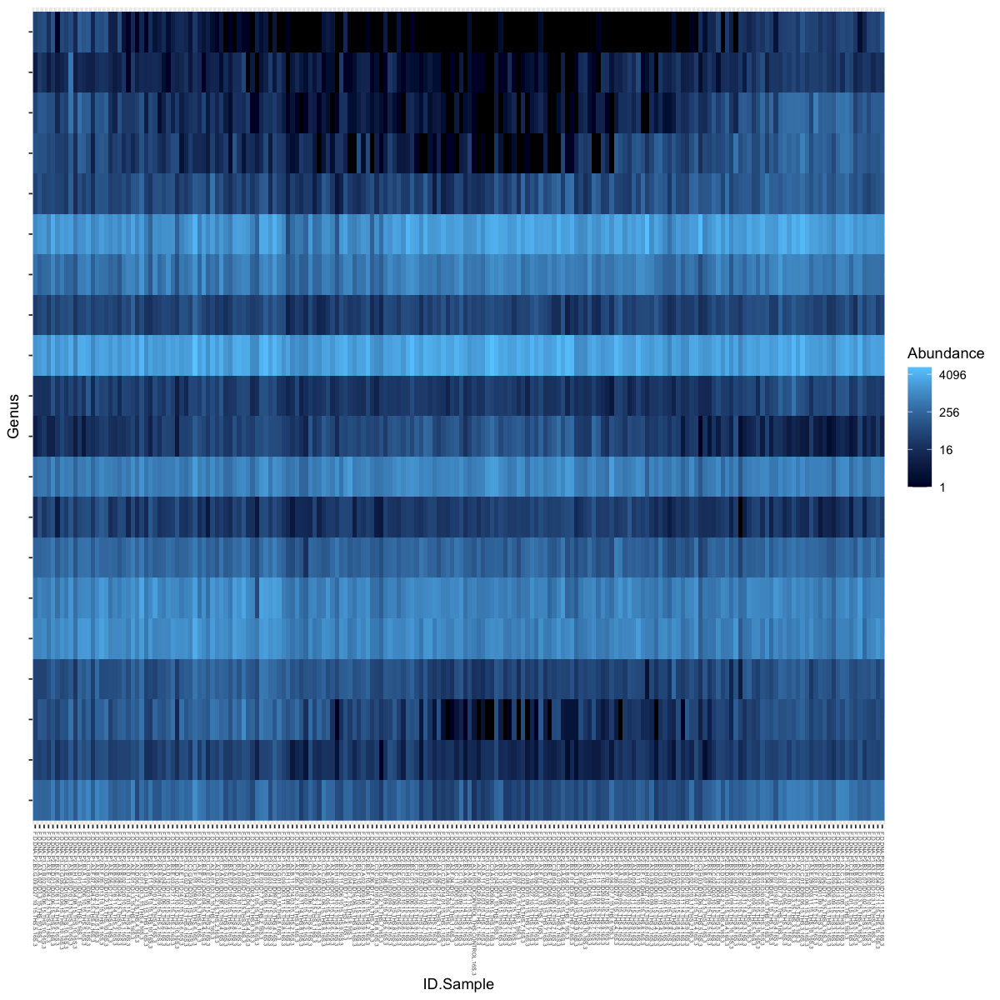

In [97]:

# Heatmap of Abundant Taxa
plot_heatmap(ps_top20, sample.label = "ID.Sample", taxa.label = "Genus")


In [100]:
BiocManager::install("decontam")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.18 (BiocManager 1.30.25), R 4.3.2 (2023-10-31)

Installing package(s) 'decontam'




The downloaded binary packages are in
	/var/folders/h9/ztr_ngd975x6ktdlxp1_yhcc0000gn/T//RtmpC8s7M6/downloaded_packages


Old packages: 'Hmisc', 'R.oo', 'Rcpp', 'curl', 'fs', 'gss', 'gtable', 'igraph',
  'pkgbuild', 'ps', 'quantreg', 'rgl', 'rmarkdown', 'rstudioapi', 'slam',
  'tinytex', 'withr', 'xfun'



In [111]:
# There's no control samples

# # Detect Potential Contaminants
# library(decontam)
# sample_data(ps)$is.neg <- sample_data(ps)$SampleType == "Control"
# contam_df <- isContaminant(ps, method = "prevalence", neg = "is.neg")
# ps_decontam <- prune_taxa(!contam_df$contaminant, ps)

In [112]:

# Summarize Key Statistics

# Most Abundant Taxa
taxa_sums <- sort(taxa_sums(ps_filtered), decreasing = TRUE)
head(taxa_sums)


ASV_1 ASV_2 ASV_3 ASV_4 ASV_5 ASV_6 
21061 13543  9754  7969  7379  7153

In [113]:

# Diversity Indices per Sample
alpha_diversity <- estimate_richness(ps_filtered, measures = c("Observed", "Shannon", "Simpson"))
head(alpha_diversity)


,Observed,Shannon,Simpson
,<dbl>,<dbl>,<dbl>
F.D.DNA.P1.A3.A.01.ID3.3.15.THS.2.16S.3,1889,6.464708,0.9964712
F.D.DNA.P1.A3.A.02.ID3.3.15.THS.10.16S.3,2026,7.037534,0.9984074
F.D.DNA.P1.A3.A.03.ID10.3.15.THS.9.16S.3,1538,5.852518,0.9883229
F.D.DNA.P1.A3.A.04.ID7.7.15.THS.6.16S.3,1647,6.482419,0.9962454
F.D.DNA.P1.A3.A.05.ID10.2.15.THS.4.16S.3,1756,6.431030,0.9955306
F.D.DNA.P1.A3.A.06.ID17.2.15.THS.1.16S.3,1918,6.737948,0.9972324


## Ordination with Phyloseq

In [82]:
nmds_res_bray <- ordinate(pseq, method = "NMDS", distance = "bray")
nmds_res_jsd <- ordinate(pseq, method = "NMDS", distance = "jsd")

Square root transformation
Wisconsin double standardization
Run 0 stress 0.1189213 
Run 1 stress 0.1306455 
Run 2 stress 0.1345828 
Run 3 stress 0.1191149 
... Procrustes: rmse 0.004517424  max resid 0.06148091 
Run 4 stress 0.1396864 
Run 5 stress 0.1352016 
Run 6 stress 0.1265464 
Run 7 stress 0.1348559 
Run 8 stress 0.1247353 
Run 9 stress 0.1345828 
Run 10 stress 0.1349643 
Run 11 stress 0.1404303 
Run 12 stress 0.1354768 
Run 13 stress 0.1261999 
Run 14 stress 0.1524255 
Run 15 stress 0.118922 
... Procrustes: rmse 0.0002995074  max resid 0.003734886 
... Similar to previous best
Run 16 stress 0.1261987 
Run 17 stress 0.1315214 
Run 18 stress 0.1297485 
Run 19 stress 0.1514481 
Run 20 stress 0.1394884 
*** Best solution repeated 1 times
Run 0 stress 0.1187044 
Run 1 stress 0.119128 
... Procrustes: rmse 0.00609351  max resid 0.08297898 
Run 2 stress 0.1489986 
Run 3 stress 0.137075 
Run 4 stress 0.1196897 
Run 5 stress 0.1196897 
Run 6 stress 0.1262457 
Run 7 stress 0.1187045 
...

In [84]:
nmds_res_jsd <- ordinate(pseq, method = "NMDS", distance = "aitchinson")

ERROR: Error in eval(parse(text = method)): object 'aitchinson' not found


"aitchinson" is not a valid argument for the distance option in the `ordiante` phyloseq function call

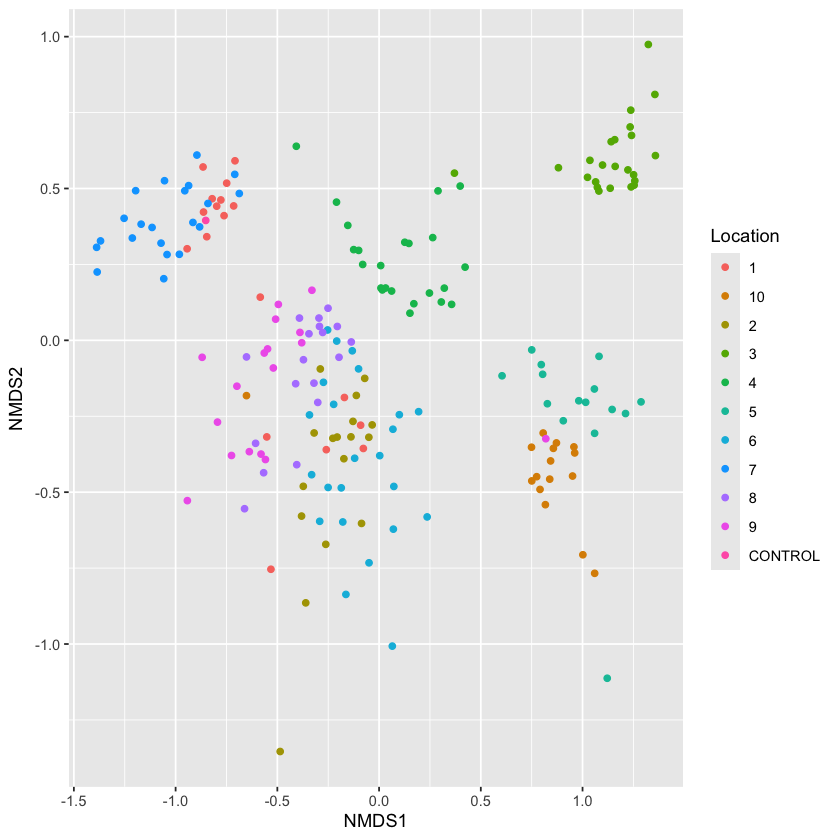

In [81]:
plot_ordination(pseq, nmds_res_bray, color = "Location")

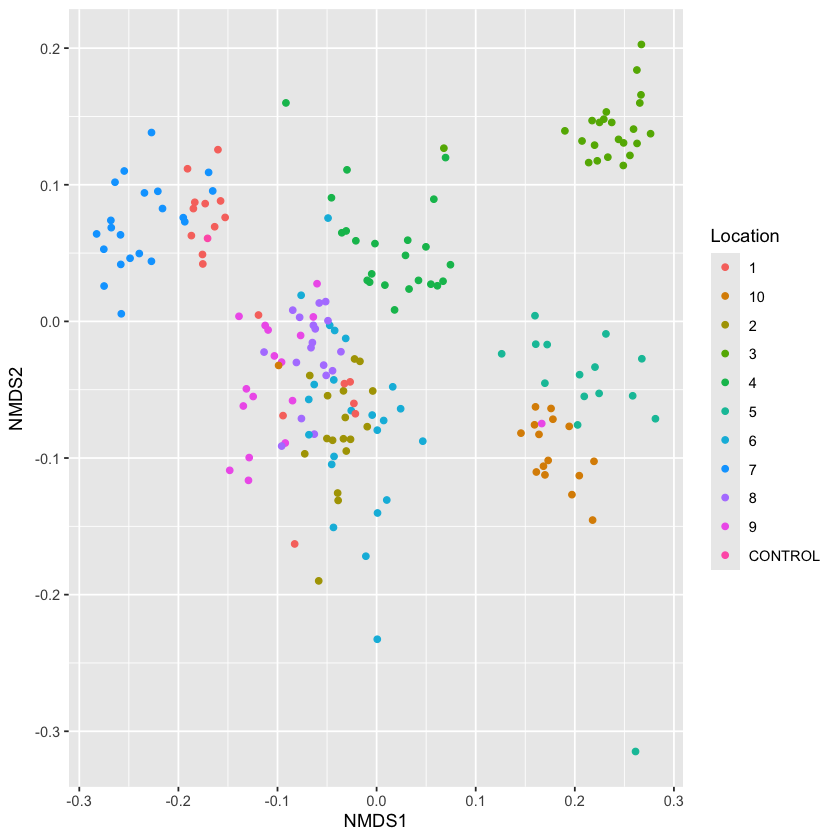

In [ ]:
plot_ordination(pseq, nmds_res_jsd, color = "Location")

## Options for compositional data, pseudocounts, distance and dimensionality reduction

* 0 substitution: cmultRepl, Distance: Aitchinson (compositional transformation: CLR, distance: euclidean)
* 0 substitution: None, Compositional Transformation: CLR, Distance: JSD


## Exploring microViz

In [16]:
# if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")
# BiocManager::install(c("phyloseq", "microbiome", "ComplexHeatmap"), update = FALSE)

In [17]:
# install.packages(
#   "microViz",
#   repos = c(davidbarnett = "https://david-barnett.r-universe.dev", getOption("repos"))
# )

In [18]:
# install.packages("ggtext") # for rotated labels on ord_plot() 
# install.packages("ggraph") # for taxatree_plots()
# install.packages("DT") # for tax_fix_interactive()
# install.packages("corncob") # for beta binomial models in tax_model()

In [13]:
library(microViz)

Warning message:
"package 'microViz' was built under R version 4.3.3"


microViz version 0.12.4 - Copyright (C) 2021-2024 David Barnett
! Website: https://david-barnett.github.io/microViz
v Useful?  For citation details, run: `citation("microViz")`
x Silence? `suppressPackageStartupMessages(library(microViz))`


In [14]:
pseq_t <- pseq %>%
    tax_fix() %>%
    phyloseq_validate()

In [15]:
ord_explore(pseq_t)

To stop the app: Click red stop button or hit Esc in the console

Loading required package: shiny

Warning message:
"package 'shiny' was built under R version 4.3.3"

Listening on http://127.0.0.1:4492

Warning message:
"Removed 1 row containing missing values or values outside the scale range
(`geom_interactive_point()`)."
Warning message:
"Removed 1 row containing missing values or values outside the scale range
(`geom_interactive_point()`)."
Warning message:
"Removed 1 row containing missing values or values outside the scale range
(`geom_interactive_point()`)."
Warning message:
"Removed 1 row containing missing values or values outside the scale range
(`geom_interactive_point()`)."
Too few points to calculate an ellipse
Warning message:
"Removed 1 row containing missing values or values outside the scale range
(`geom_interactive_point()`)."
Warning message:
"Removed 1 row containing missing values or values outside the scale range
(`geom_path()`)."
Too few points to calculate an el

### 
* No transformation + Jensen Divergence Dintance + NMDS
Samples cluster very well in tree holes
* Robust CLR + Ecludian distance (Aitchison) + NMDS
Samples don't cluster as well

## Create NMDS through vegan MDS method

In [14]:
# pseq.bray <- distance(pseq, method = "bray")

In [ ]:
pseq.radist <- vegdist(t(otu.pseq), method = "robust.aitchison")
pseq.radist

                                               F.D.DNA.P1.A3.A.01.ID3.3.15.THS.2.16S.3
F.D.DNA.P1.A3.A.02.ID3.3.15.THS.10.16S.3                                      59.64228
F.D.DNA.P1.A3.A.03.ID10.3.15.THS.9.16S.3                                      57.72379
F.D.DNA.P1.A3.A.04.ID7.7.15.THS.6.16S.3                                       56.96802
F.D.DNA.P1.A3.A.05.ID10.2.15.THS.4.16S.3                                      56.64595
F.D.DNA.P1.A3.A.06.ID17.2.15.THS.1.16S.3                                      53.33164
F.D.DNA.P1.A3.A.07.ID24.2.15.THS.1.16S.3                                      51.91584
F.D.DNA.P1.A3.A.08.ID24.2.15.THS.9.16S.3                                      50.77119
F.D.DNA.P1.A3.A.09.ID03.11.15.THS.6.16S.3                                     52.18948
F.D.DNA.P1.A3.A.10.ID29.09.15.THS.4.16S.3                                     65.69192
F.D.DNA.P1.A3.A.11.ID14.03.15.THS.1.16S.3                                     57.25102
F.D.DNA.P1.A3.A.12.ID11.05.15.THS.1.16S.3  

Square root transformation
Wisconsin double standardization
Run 0 stress 0.1198646 
Run 1 stress 0.1620971 
Run 2 stress 0.1292707 
Run 3 stress 0.1610733 
Run 4 stress 0.1511961 
Run 5 stress 0.1250122 
Run 6 stress 0.4165645 
Run 7 stress 0.1250134 
Run 8 stress 0.1315784 
Run 9 stress 0.1249526 
Run 10 stress 0.1306107 
Run 11 stress 0.1337484 
Run 12 stress 0.1221677 
Run 13 stress 0.2752496 
Run 14 stress 0.1248769 
Run 15 stress 0.1198661 
... Procrustes: rmse 0.000304196  max resid 0.003766316 
... Similar to previous best
Run 16 stress 0.1360566 
Run 17 stress 0.1290461 
Run 18 stress 0.1221677 
Run 19 stress 0.1540747 
Run 20 stress 0.1483736 
*** Best solution repeated 1 times


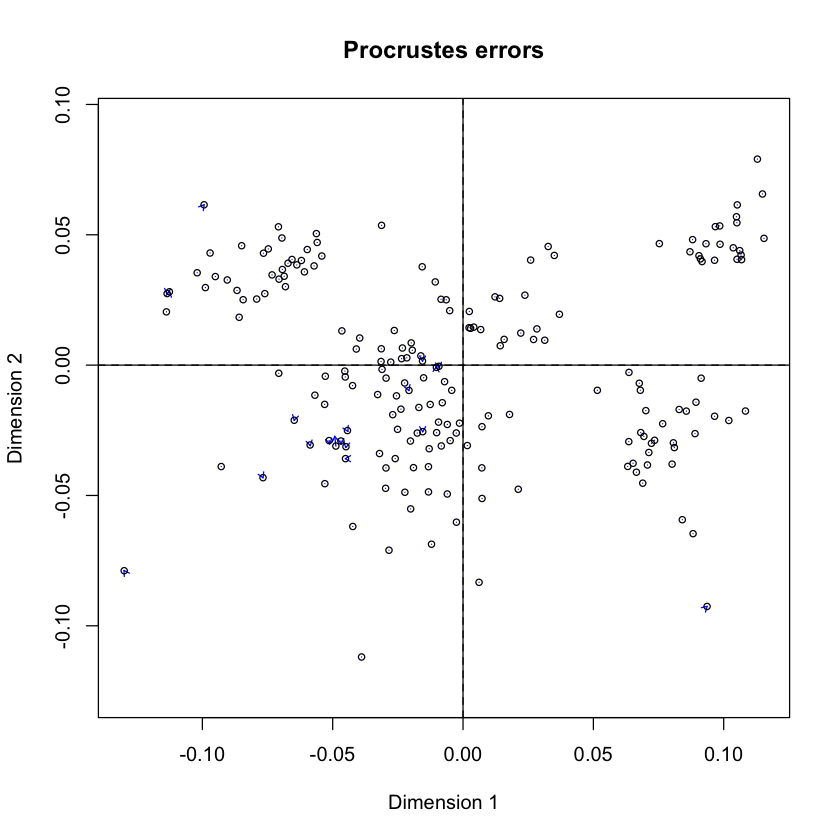

In [ ]:
nmdsRes.bray <- metaMDS(t(otu.pseq),k = 2, plot = TRUE, try = 100)

In [ ]:
nmdsRes.r_atch <- metaMDS(t(otu.pseq), k = 2, plot = FALSE,
                    distance = "robust.aitchison", try = 100)

Square root transformation
Wisconsin double standardization
Run 0 stress 0.2593529 
Run 1 stress 0.2758924 
Run 2 stress 0.2799596 
Run 3 stress 0.286539 
Run 4 stress 0.2768504 
Run 5 stress 0.2787478 
Run 6 stress 0.264702 
Run 7 stress 0.2659583 
Run 8 stress 0.272827 
Run 9 stress 0.2680878 
Run 10 stress 0.2693368 
Run 11 stress 0.2947792 
Run 12 stress 0.2621061 
Run 13 stress 0.2697717 
Run 14 stress 0.2737699 
Run 15 stress 0.2949776 
Run 16 stress 0.2666335 
Run 17 stress 0.2761806 
Run 18 stress 0.2769238 
Run 19 stress 0.2716828 
Run 20 stress 0.2779627 
*** Best solution was not repeated -- monoMDS stopping criteria:
     6: no. of iterations >= maxit
    14: stress ratio > sratmax


In [ ]:
nmdsRes.r_atch


Call:
metaMDS(comm = t(otu.pseq), distance = "robust.aitchison", k = 2,      try = 100, plot = FALSE) 

global Multidimensional Scaling using monoMDS

Data:     wisconsin(sqrt(t(otu.pseq))) 
Distance: robust.aitchison 

Dimensions: 2 
Stress:     0.2593529 
Stress type 1, weak ties
Best solution was not repeated after 20 tries
The best solution was from try 0 (metric scaling or null solution)
Scaling: centring, PC rotation 
Species: expanded scores based on 'wisconsin(sqrt(t(otu.pseq)))' 


## Checking the pseudocounts and alternatives

In [37]:
# Original approach (pseudocount of 1)
nmds_pseq_20 <- metaMDS(comm = t(otu.pseq + 0.001), distance = "robust.aitchison", k = 2, try = 100, plot = FALSE)

# Try smaller pseudocounts
nmds_pseq_40 <- metaMDS(comm = t(otu.pseq + 0.00001), distance = "robust.aitchison", k = 2, try = 100, plot = FALSE)
nmds_pseq_90 <- metaMDS(comm = t(otu.pseq + 0.0000000001), distance = "robust.aitchison", k = 2, try = 100, plot = FALSE)

# Compare stress values
cat("Stress with pseudocount 0.001:", nmds_pseq_20$stress, "\n")
cat("Stress with pseudocount 0.00001:", nmds_pseq_40$stress, "\n")
cat("Stress with pseudocount 0.0000000001:", nmds_pseq_90$stress, "\n")

Square root transformation
Wisconsin double standardization
Run 0 stress 0.1742075 
Run 1 stress 0.1926433 
Run 2 stress 0.1782913 
Run 3 stress 0.1962084 
Run 4 stress 0.1924886 
Run 5 stress 0.1864468 
Run 6 stress 0.1794255 
Run 7 stress 0.1737308 
... New best solution
... Procrustes: rmse 0.01675756  max resid 0.1691819 
Run 8 stress 0.1866183 
Run 9 stress 0.2002155 
Run 10 stress 0.1732321 
... New best solution
... Procrustes: rmse 0.01279838  max resid 0.1485094 
Run 11 stress 0.1758667 
Run 12 stress 0.1778705 
Run 13 stress 0.1829526 
Run 14 stress 0.218053 
Run 15 stress 0.1932644 
Run 16 stress 0.1878475 
Run 17 stress 0.1766327 
Run 18 stress 0.1705869 
... New best solution
... Procrustes: rmse 0.0127593  max resid 0.1278109 
Run 19 stress 0.1910918 
Run 20 stress 0.179007 
*** Best solution was not repeated -- monoMDS stopping criteria:
    12: stress ratio > sratmax
     8: scale factor of the gradient < sfgrmin
Square root transformation
Wisconsin double standardizati

In [ ]:
# Try Bayesian-multiplicative replacement
otu_cmultRepl <- cmultRepl(t(otu.pseq), method="CZM", output="p-counts")
nmds_cmultRepl <- metaMDS(comm = otu_cmultRepl, distance = "robust.aitchison", k = 2, try = 100, plot = FALSE)
cat("Stress with CZM replacement:", nmds_cmultRepl$stress, "\n")

Warning message in cmultRepl(t(otu.pseq), method = "CZM", output = "p-counts"):
"Column no. 11 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 32 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 45 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 55 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 57 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 63 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 66 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 75 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 76 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
C

No. adjusted imputations:  96049 
Square root transformation
Wisconsin double standardization
Run 0 stress 0.1647844 
Run 1 stress 0.1934294 
Run 2 stress 0.1798048 
Run 3 stress 0.1670879 
Run 4 stress 0.1784464 
Run 5 stress 0.1759213 
Run 6 stress 0.1896229 
Run 7 stress 0.1800778 
Run 8 stress 0.1883871 
Run 9 stress 0.167857 
Run 10 stress 0.1703626 
Run 11 stress 0.1647421 
... New best solution
... Procrustes: rmse 0.0147691  max resid 0.1555963 
Run 12 stress 0.1672077 
Run 13 stress 0.1992811 
Run 14 stress 0.1733901 
Run 15 stress 0.1797872 
Run 16 stress 0.1822326 
Run 17 stress 0.1722299 
Run 18 stress 0.1651542 
... Procrustes: rmse 0.01717941  max resid 0.1539758 
Run 19 stress 0.1666728 
Run 20 stress 0.164707 
... New best solution
... Procrustes: rmse 0.01835252  max resid 0.172215 
*** Best solution was not repeated -- monoMDS stopping criteria:
     1: no. of iterations >= maxit
    10: stress ratio > sratmax
     9: scale factor of the gradient < sfgrmin
Stress with

Warning message:
"Removed 1258543 rows containing non-finite outside the scale range
(`stat_density()`)."


ERROR: Error in h(simpleError(msg, call)): error in evaluating the argument 'x' in selecting a method for function 'plot': object 'nmds_pseq1' not found


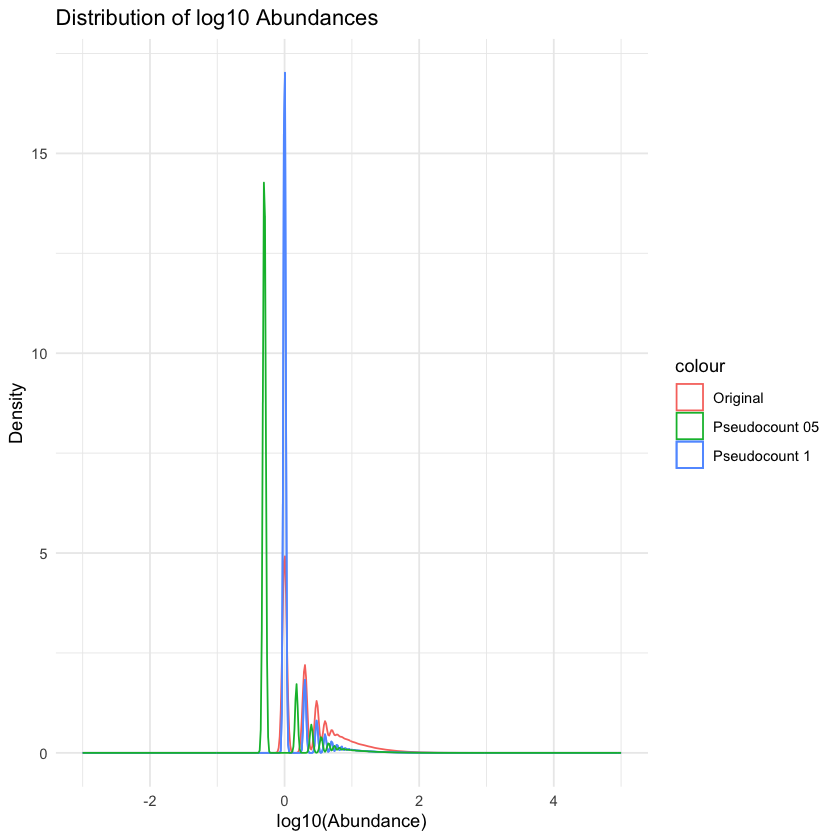

In [39]:

# Visualize impact of pseudocount
library(tidyr)

otu_long <- pivot_longer(as.data.frame(otu.pseq), cols = everything(), names_to = "OTU", values_to = "Abundance")
otu_long_pseq1 <- pivot_longer(as.data.frame(otu.pseq + 1), cols = everything(), names_to = "OTU", values_to = "Abundance")
otu_long_pseq05 <- pivot_longer(as.data.frame(otu.pseq + 0.5), cols = everything(), names_to = "OTU", values_to = "Abundance")
otu_long_pseq001 <- pivot_longer(as.data.frame(otu.pseq + 0.01), cols = everything(), names_to = "OTU", values_to = "Abundance")
otu_long_pseq40 <- pivot_longer(as.data.frame(otu.pseq + 0.00001), cols = everything(), names_to = "OTU", values_to = "Abundance")
otu_long_pseq90 <- pivot_longer(as.data.frame(otu.pseq + 0.0000000001), cols = everything(), names_to = "OTU", values_to = "Abundance")
otu_long_cmultRepl <- pivot_longer(as.data.frame(otu_cmultRepl), cols = everything(), names_to = "OTU", values_to = "Abundance")

ggplot() +
  geom_density(data = otu_long, aes(x = log10(Abundance), color = "Original"), alpha = 0.5) +
  geom_density(data = otu_long_pseq1, aes(x = log10(Abundance), color = "Pseudocount 1"), alpha = 0.5) +    geom_density(data = otu_long_pseq1, aes(x = log10(Abundance), color = "Pseudocount 1"), alpha = 0.5) +
  geom_density(data = otu_long_pseq05, aes(x = log10(Abundance), color = "Pseudocount 05"), alpha = 0.5) +
  # geom_density(data = otu_long_pseq001, aes(x = log10(Abundance), color = "Pseudocount 001"), alpha = 0.5) +
  # geom_density(data = otu_long_pseq40, aes(x = log10(Abundance), color = "Pseudocount 40"), alpha = 0.5) +
  # geom_density(data = otu_long_pseq90, aes(x = log10(Abundance), color = "Pseudocount 90"), alpha = 0.5) +
  # geom_density(data = otu_long_cmultRepl, aes(x = log10(Abundance), color = "Pseudocount cmultRepl"), alpha = 0.5) +

  scale_x_continuous(limits = c(-3, 5)) +
  theme_minimal() +
  labs(title = "Distribution of log10 Abundances", x = "log10(Abundance)", y = "Density")

# Compare NMDS plots
plot(nmds_pseq1, main = "NMDS with Pseudocount 1")
plot(nmds_pseq05, main = "NMDS with Pseudocount 0.5")
plot(nmds_pseq01, main = "NMDS with Pseudocount 0.1")
plot(nmds_cmultRepl, main = "NMDS with CZM Replacement")

### cmultRepl wins

## Benchmarking different distances

In [30]:
library(ape)
library(GUniFrac)
library(phangorn)
# library(compositions)


Attaching package: 'phangorn'


The following objects are masked from 'package:vegan':

    diversity, treedist




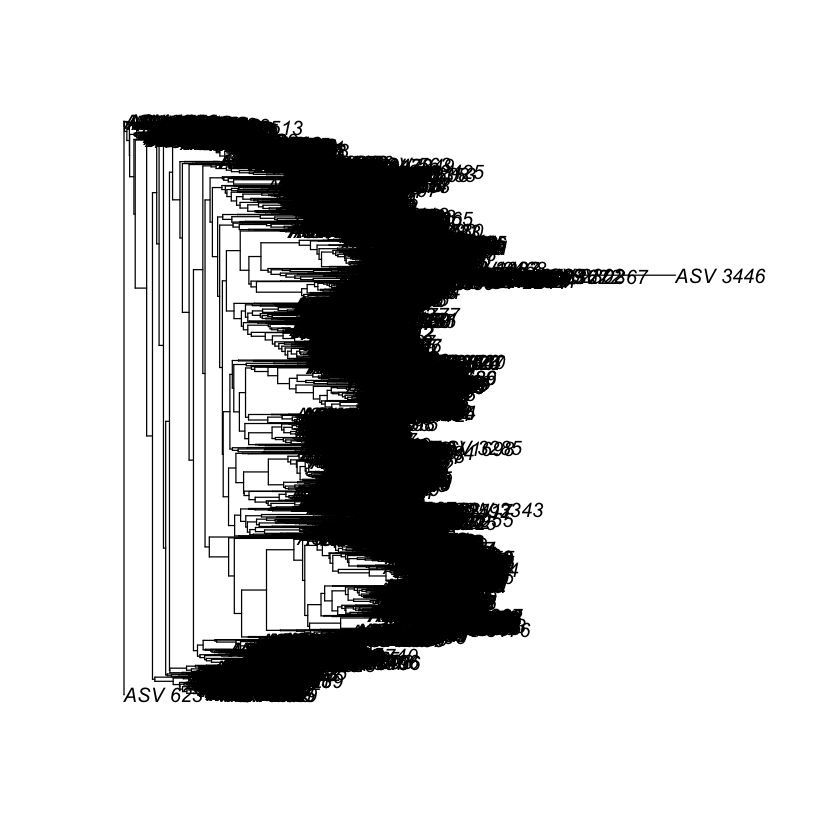

In [24]:
# Read the phylogenetic tree
tree <- read.tree(here("3.2_Neutral_Stegen", "figures", "nj_tree_stegen.tre"))
plot(tree)

In [25]:
# Check if the tree is rooted
is_rooted <- is.rooted(tree)
cat("Is the tree rooted?", is_rooted, "\n")

Is the tree rooted? FALSE 


In [31]:
tree_rooted <- midpoint(tree)

In [33]:
# Prune the tree to match the OTU table
tree_pruned <- prune_taxa(taxa_names(otu.pseq), tree_rooted)

In [20]:
# Function to calculate modified Gower distance
mod.gower <- function(x) {
    x <- decostand(x, "pa")  # Convert to presence/absence
    d <- vegdist(x, "gower")
    return(d)
}

In [59]:
otu.f <- otu.pseq[, colSums(otu.pseq) > 0]

In [61]:
dim(otu.f)
dim(otu.pseq)

[1] 8205  195

[1] 8205  195

In [72]:
# Calculate distances
otu_cmultRepl <- cmultRepl(t(otu.f), method="CZM", output="p-counts")
dist_robust_aitchison <- vegdist(otu_cmultRepl, method = "robust.aitchison")
dist_bray <- vegdist(otu_cmultRepl, method = "bray")
dist_jaccard <- vegdist(t(otu.f), method = "jaccard", binary = TRUE)
dist_mod_gower <- mod.gower(otu_cmultRepl)

Warning message in cmultRepl(t(otu.f), method = "CZM", output = "p-counts"):
"Column no. 11 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 32 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 45 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 55 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 57 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 63 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 66 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 75 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 76 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Colu

No. adjusted imputations:  96049 


In [34]:
# Names between otu table and tree don't match, giving up for now

# Calculate UniFrac distances if you have a phylogenetic tree
# If not, you can skip this part
# unifrac_dist <- GUniFrac(t(otu.pseq), tree_pruned, alpha = c(0, 0.5, 1))
# dist_unweighted_unifrac <- unifrac_dist$unifracs[, , "d_UW"]
# dist_weighted_unifrac <- unifrac_dist$unifracs[, , "d_1"]

ERROR: Error in GUniFrac(t(otu.pseq), tree_pruned, alpha = c(0, 0.5, 1)): The OTU table contains unknown OTUs! OTU names
						in the OTU table and the tree should match!


In [74]:
# Perform NMDS with each distance metric
nmds_robust_aitchison <- metaMDS(dist_robust_aitchison, k = 2, trymax = 100)
nmds_bray <- metaMDS(dist_bray, k = 2, trymax = 100)
nmds_jaccard <- metaMDS(dist_jaccard, k = 2, trymax = 100)
nmds_mod_gower <- metaMDS(dist_mod_gower, k = 2, trymax = 100)
# nmds_unweighted_unifrac <- metaMDS(dist_unweighted_unifrac, k = 2, trymax = 100)
# nmds_weighted_unifrac <- metaMDS(dist_weighted_unifrac, k = 2, trymax = 100)

Run 0 stress 0.1647844 
Run 1 stress 0.1643757 
... New best solution
... Procrustes: rmse 0.01919009  max resid 0.1726481 
Run 2 stress 0.1935295 
Run 3 stress 0.1676524 
Run 4 stress 0.177172 
Run 5 stress 0.1663543 
Run 6 stress 0.1640441 
... New best solution
... Procrustes: rmse 0.01956897  max resid 0.1544181 
Run 7 stress 0.1644414 
... Procrustes: rmse 0.02211592  max resid 0.1700044 
Run 8 stress 0.1789714 
Run 9 stress 0.1740263 
Run 10 stress 0.1829183 
Run 11 stress 0.1708864 
Run 12 stress 0.1709634 
Run 13 stress 0.2053479 
Run 14 stress 0.1677747 
Run 15 stress 0.1773753 
Run 16 stress 0.1672163 
Run 17 stress 0.167088 
Run 18 stress 0.1764948 
Run 19 stress 0.180517 
Run 20 stress 0.182462 
Run 21 stress 0.1788663 
Run 22 stress 0.2027391 
Run 23 stress 0.1868256 
Run 24 stress 0.1654148 
Run 25 stress 0.1837718 
Run 26 stress 0.1593967 
... New best solution
... Procrustes: rmse 0.01315981  max resid 0.1395595 
Run 27 stress 0.1680652 
Run 28 stress 0.1788996 
Run 29 

ERROR: Error in monoMDS(dist, y = cmdscale(dist, k = k), k = k, maxit = maxit, : 'dist' cannot be all zero (all points are identical)


In [75]:
# Compare stress values
cat("Stress values:\n")
cat("Robust Aitchison:", nmds_robust_aitchison$stress, "\n")
cat("Bray-Curtis:", nmds_bray$stress, "\n")
cat("Jaccard:", nmds_jaccard$stress, "\n")
cat("Modified Gower:", nmds_mod_gower$stress, "\n")
# cat("Unweighted UniFrac:", nmds_unweighted_unifrac$stress, "\n")
# cat("Weighted UniFrac:", nmds_weighted_unifrac$stress, "\n")

Stress values:
Robust Aitchison: 0.1593967 
Bray-Curtis: 0.1737284 
Jaccard: 0.1181199 
Modified Gower: 0.1563209 


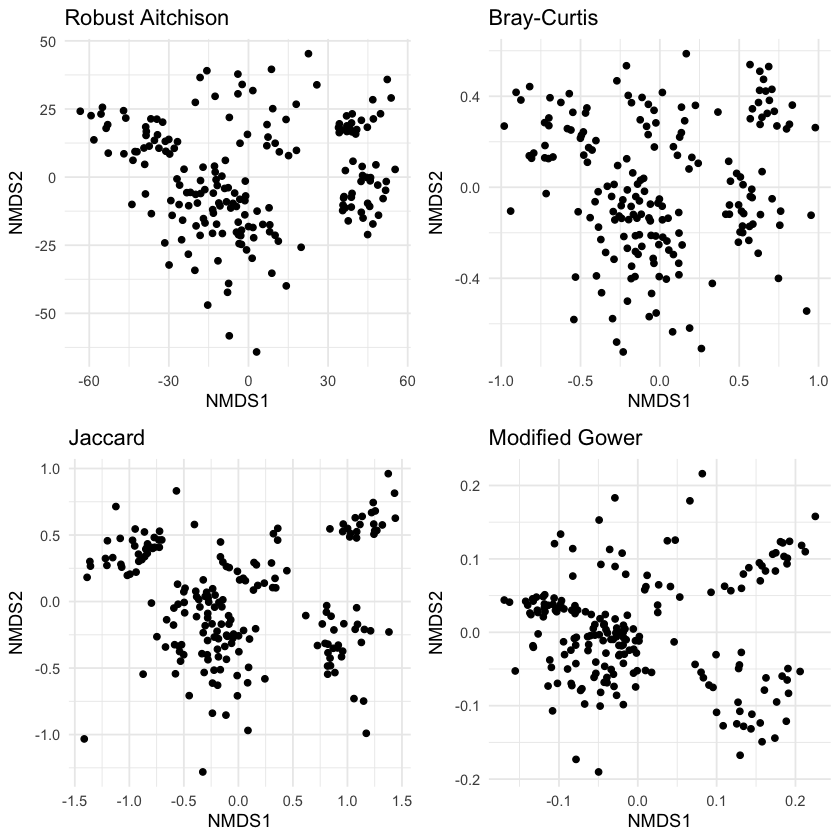

In [76]:
# Function to create NMDS plot
plot_nmds <- function(nmds_result, title) {
    data <- as.data.frame(scores(nmds_result))
    ggplot(data, aes(x = NMDS1, y = NMDS2)) +
        geom_point() +
        theme_minimal() +
        ggtitle(title)
}

# Create NMDS plots
plot_robust_aitchison <- plot_nmds(nmds_robust_aitchison, "Robust Aitchison")
plot_bray <- plot_nmds(nmds_bray, "Bray-Curtis")
plot_jaccard <- plot_nmds(nmds_jaccard, "Jaccard")
plot_mod_gower <- plot_nmds(nmds_mod_gower, "Modified Gower")
# plot_unweighted_unifrac <- plot_nmds(nmds_unweighted_unifrac, "Unweighted UniFrac")
# plot_weighted_unifrac <- plot_nmds(nmds_weighted_unifrac, "Weighted UniFrac")

# Combine plots
library(gridExtra)
grid.arrange(plot_robust_aitchison, plot_bray, plot_jaccard, plot_mod_gower, ncol = 2)

In [64]:
# Mantel test to compare distance matrices
mantel_results <- list(
    # "Robust Aitchison vs Bray-Curtis" = mantel(dist_robust_aitchison, dist_bray),
    # "Robust Aitchison vs Jaccard" = mantel(dist_robust_aitchison, dist_jaccard),
    # "Robust Aitchison vs Modified Gower" = mantel(dist_robust_aitchison, dist_mod_gower),
    "Bray-Curtis vs Jaccard" = mantel(dist_bray, dist_jaccard),
    "Bray-Curtis vs Modified Gower" = mantel(dist_bray, dist_mod_gower),
    "Jaccard vs Modified Gower" = mantel(dist_jaccard, dist_mod_gower)
)

In [65]:

# Print Mantel test results
for (name in names(mantel_results)) {
    cat(name, "- Correlation:", mantel_results[[name]]$statistic, 
        "p-value:", mantel_results[[name]]$signif, "\n")
}

Bray-Curtis vs Jaccard - Correlation: 0.9612824 p-value: 0.001 
Bray-Curtis vs Modified Gower - Correlation: 0.7021499 p-value: 0.001 
Jaccard vs Modified Gower - Correlation: 0.6744628 p-value: 0.001 


### Jaccard has the smallest stress in the NMDS 
but only considers the presence of shared species. I'll use Atchison with the cmultRepl transformation to get rid of the zeros

## Compare with 3 dimensional reduction and plotting with ggplot

In [151]:
# Try a 3D solution
otu_cmultRepl <- cmultRepl(t(otu.pseq), method="CZM", output="p-counts")
nmds_3d <- metaMDS(comm = otu_cmultRepl, distance = "robust.aitchison", k = 3, try = 200, plot = FALSE)
print(nmds_3d)

Warning message in cmultRepl(t(otu.pseq), method = "CZM", output = "p-counts"):
"Column no. 11 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 32 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 45 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 55 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 57 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 63 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 66 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 75 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 76 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
C

No. adjusted imputations:  96049 
Square root transformation
Wisconsin double standardization
Run 0 stress 0.09975404 
Run 1 stress 0.09975402 
... New best solution
... Procrustes: rmse 1.834907e-05  max resid 0.0001747317 
... Similar to previous best
Run 2 stress 0.1059154 
Run 3 stress 0.09975414 
... Procrustes: rmse 7.493259e-05  max resid 0.0005207305 
... Similar to previous best
Run 4 stress 0.09989679 
... Procrustes: rmse 0.004923642  max resid 0.03750206 
Run 5 stress 0.1185545 
Run 6 stress 0.09989398 
... Procrustes: rmse 0.004020459  max resid 0.03168026 
Run 7 stress 0.1019097 
Run 8 stress 0.09989779 
... Procrustes: rmse 0.005099981  max resid 0.03792549 
Run 9 stress 0.09989792 
... Procrustes: rmse 0.005126155  max resid 0.03802323 
Run 10 stress 0.09989774 
... Procrustes: rmse 0.005077763  max resid 0.03783013 
Run 11 stress 0.1038483 
Run 12 stress 0.1054609 
Run 13 stress 0.09975404 
... Procrustes: rmse 5.492709e-05  max resid 0.0003072441 
... Similar to previ

In [152]:
nmds_3d$stress

[1] 0.09975402

In [153]:
# library(rgl)
# plot3d(nmds_3d$points[,1], nmds_3d$points[,2], nmds_3d$points[,3], 
#        xlab = "NMDS1", ylab = "NMDS2", zlab = "NMDS3")

In [154]:
# Add Location information to nmds_coords
nmds_coords$Location <- meta$Location[match(rownames(nmds_coords), rownames(meta))]

# Create a color palette for locations
location_colors <- setNames(scales::hue_pal()(n_distinct(nmds_coords$Location)), unique(nmds_coords$Location))

# Create an interactive 3D scatter plot with colors by Location
p <- plot_ly(nmds_coords, 
             x = ~MDS1, y = ~MDS2, z = ~MDS3, 
             type = "scatter3d", 
             mode = "markers",
             marker = list(size = 5),
             color = ~Location,
             colors = location_colors,
             text = ~paste("Sample:", rownames(nmds_coords), "<br>Location:", Location),
             hoverinfo = "text") %>%
    layout(scene = list(xaxis = list(title = "NMDS1"),
                        yaxis = list(title = "NMDS2"),
                        zaxis = list(title = "NMDS3")),
           legend = list(title = list(text = "Location")))

# Display the plot
p

HTML widgets cannot be represented in plain text (need html)

## Adding metacommunity and others

In [134]:
meta.nona <- meta[!(is.na(meta$Dirichlet)), ]
otu.dna_nona <- otu.pseq[, rownames(meta.nona)]
dim(meta.nona)
dim(otu.dna_nona)

[1] 163  34

[1] 8205  163

In [155]:
otu_cmultRepl <- cmultRepl(t(otu.dna_nona), method="CZM", output="p-counts")
nmdsRoAit.res <- metaMDS(otu_cmultRepl, k = 2, plot = FALSE,
                    distance = "robust.aitchison", try = 100)

# put the points in a new dataframe
nmdsRoAit.df <- data.frame(x = nmdsRoAit.res$points[,1], y = nmdsRes$points[,2])

Warning message in cmultRepl(t(otu.dna_nona), method = "CZM", output = "p-counts"):
"Column no. 11 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 45 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 55 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 63 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 66 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 75 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 76 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 95 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 104 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delet

No. adjusted imputations:  45828 
Square root transformation
Wisconsin double standardization
Run 0 stress 0.1612618 
Run 1 stress 0.1794007 
Run 2 stress 0.1677509 
Run 3 stress 0.1638497 
Run 4 stress 0.1787428 
Run 5 stress 0.1643935 
Run 6 stress 0.1674884 
Run 7 stress 0.1669923 
Run 8 stress 0.1663704 
Run 9 stress 0.1782631 
Run 10 stress 0.1759208 
Run 11 stress 0.1912043 
Run 12 stress 0.1762463 
Run 13 stress 0.1643934 
Run 14 stress 0.1817088 
Run 15 stress 0.191251 
Run 16 stress 0.1696454 
Run 17 stress 0.1688772 
Run 18 stress 0.1666208 
Run 19 stress 0.1649136 
Run 20 stress 0.1674331 
*** Best solution was not repeated -- monoMDS stopping criteria:
    15: stress ratio > sratmax
     5: scale factor of the gradient < sfgrmin


In [159]:
# otu_cmultRepl <- cmultRepl(t(otu.dna_nona), method = "CZM", 
#                            output = "p-counts")
dist_jsd <- distance(otu_cmultRepl, method = "jensen-shannon")

# nmdsJSD.res <- metaMDS(dist_jsd, k = 2, plot = FALSE,
#                        try = 100)

# # put the points in a new dataframe
# nmdsJSD.df <- data.frame(x = nmdsJSD.res$points[,1], y = nmdsRes$points[,2])

Warning message in cmultRepl(t(otu.dna_nona), method = "CZM", output = "p-counts"):
"Column no. 11 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 45 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 55 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 63 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 66 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 75 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 76 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 95 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delete).
Column no. 104 containing >80% zeros/unobserved values deleted (see arguments z.warning and z.delet

No. adjusted imputations:  45828 


ERROR: Error in (function (classes, fdef, mtable) : unable to find an inherited method for function 'distance' for signature '"data.frame", "character"'


In [141]:
setdiff(rownames(nmdsRes$points), rownames(meta.nona))

character(0)

In [142]:
setdiff(rownames(meta.nona), rownames(nmdsRes$points))

[1] "F.D.DNA.P3.C3.H.03.ID16.06.15.THS.5.16S.3"

In [148]:
meta.nona.f <- meta.nona[-which(rownames(meta.nona) == "F.D.DNA.P3.C3.H.03.ID16.06.15.THS.5.16S.3"), ]

In [150]:
svg(here("4.1_Niche_Envir", "nmds_location_metacommunity.svg"))
ggplot(data = nmds_df, aes(x= x, y = y))+
  geom_point(aes(data = NULL, colour = factor(meta.nona.f$Location), shape = factor(meta.nona.f$Dirichlet)))+
  scale_shape_manual(values = c(0:9))
dev.off()

pdf 
  2